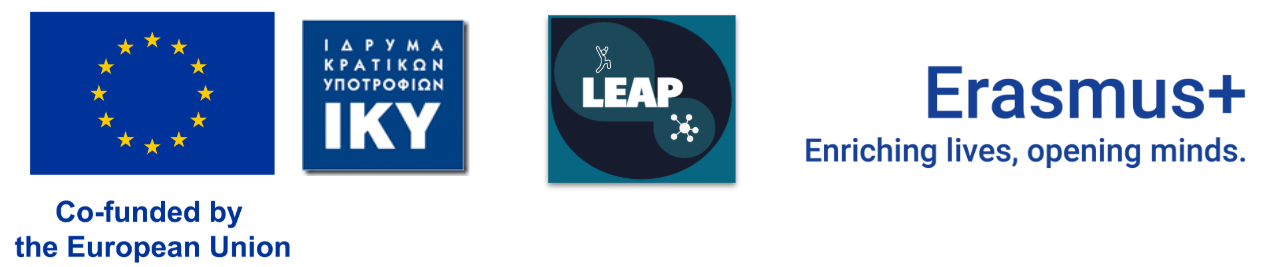

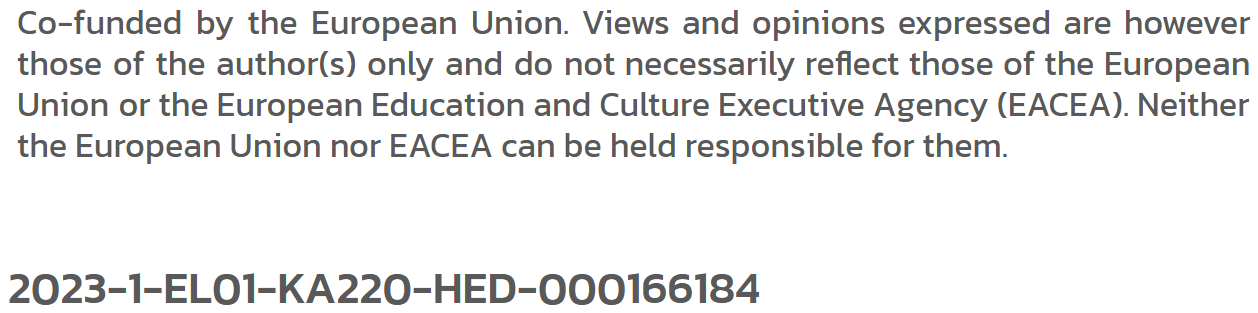

# Final Project, Option 1: Where does the CNN make its mistakes?

Software that reads handwritten numbers, such as postcodes on envelopes or account numbers on paper forms, must be judged not only on how often it is right but on where it goes wrong, because a confident misreading carries a real cost. In this project I build a convolutional neural network that recognises handwritten digits and study the mistakes it makes.

**Central question:** where does the CNN make its mistakes, and does one change to the model move them?

The data set is MNIST: 70,000 greyscale images of handwritten digits, each 28 by 28 pixels, labelled 0 to 9.

## Part A. Setup and data

Imports for the whole notebook.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

import keras
from keras import layers

### Loading the data

MNIST is downloaded from OpenML. The images come back in `X` as 70,000 rows of 784 numbers, and the labels in `y` as text, which are converted to integers.

In [2]:
X, y = fetch_openml("mnist_784", version=1, as_frame=False, return_X_y=True)
y = y.astype(int)

print("Images:", X.shape)
print("Labels:", y.shape, "| classes:", np.unique(y))

Images: (70000, 784)
Labels: (70000,) | classes: [0 1 2 3 4 5 6 7 8 9]


### Preparing the images

Each row of `X` is one image flattened into 784 numbers. Every row is reshaped back into a 28 by 28 image with a single greyscale channel, and the pixel values are scaled from 0–255 to 0–1, which helps the network train. The data is then split into a training set and a test set, keeping the class balance with `stratify`.

In [3]:
X = X.reshape(-1, 28, 28, 1).astype("float32") / 255.0

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Training images:", X_train.shape)
print("Test images:    ", X_test.shape)

Training images: (56000, 28, 28, 1)
Test images:     (14000, 28, 28, 1)


### A first look at the images

A few training images with their labels, to confirm the data loaded correctly.

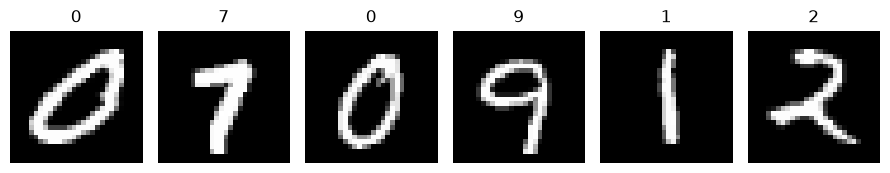

In [4]:
fig, axes = plt.subplots(1, 6, figsize=(9, 2))
for ax, image, label in zip(axes, X_train, y_train):
    ax.imshow(image.reshape(28, 28), cmap="gray")
    ax.set_title(str(label))
    ax.axis("off")
plt.tight_layout()
plt.show()

## Part B. Build and train the network

A convolutional neural network built with the Keras Sequential API. Each input image is 28 by 28 pixels with one channel.

In [5]:
# Fix the random seed so that rerunning the notebook gives comparable results.
keras.utils.set_random_seed(42)

model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.3),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax"),
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 5408)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       346,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 347,146 (1.32 MB)

 Trainable params: 347,146 (1.32 MB)

 Non-trainable params: 0 (0.00 B)

### Compile the model

Compiling sets the optimiser, the loss function and the metric tracked during training.

In [6]:
# Adam optimiser, sparse categorical crossentropy (integer labels 0 to 9),
# and accuracy as the metric.
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

### Train the model

10% of the training data is held out for validation. `EarlyStopping` halts training once the validation loss stops improving, which saves time and limits overfitting.

In [7]:
# Stop training once the validation loss has not improved for 3 epochs,
# and go back to the weights from the best epoch.
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=3, restore_best_weights=True)

history = model.fit(
    X_train, y_train,
    validation_split=0.1,
    epochs=15,
    batch_size=128,
    callbacks=[early_stop],
    verbose=2,
)

Epoch 1/15


394/394 - 6s - 14ms/step - accuracy: 0.9092 - loss: 0.3206 - val_accuracy: 0.9636 - val_loss: 0.1290


Epoch 2/15


394/394 - 4s - 10ms/step - accuracy: 0.9683 - loss: 0.1088 - val_accuracy: 0.9730 - val_loss: 0.0860


Epoch 3/15


...

394/394 - 4s - 10ms/step - accuracy: 0.9921 - loss: 0.0241 - val_accuracy: 0.9877 - val_loss: 0.0453


Epoch 12/15


394/394 - 4s - 10ms/step - accuracy: 0.9933 - loss: 0.0199 - val_accuracy: 0.9879 - val_loss: 0.0445


Epoch 13/15


394/394 - 4s - 10ms/step - accuracy: 0.9935 - loss: 0.0188 - val_accuracy: 0.9864 - val_loss: 0.0515


### Learning curves

Training and validation loss across the epochs. A validation curve that flattens or rises while the training curve keeps falling indicates overfitting.

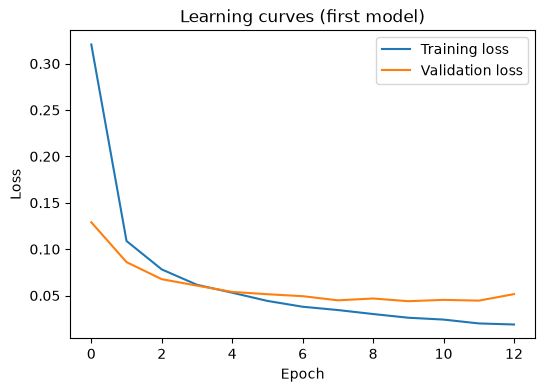

In [8]:
plt.figure(figsize=(6, 4))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Learning curves (first model)")
plt.legend()
plt.show()

## Part C. Reading the mistakes

Accuracy on the test set, images the model never saw during training, gives a reliable estimate of how it performs on new images.

In [9]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"Test accuracy: {test_accuracy:.4f}")

y_pred = model.predict(X_test, verbose=0).argmax(axis=1)

Test accuracy: 0.9864


### The confusion matrix

Each row is a true digit and each column is the predicted digit. The diagonal holds the correct predictions; every off-diagonal cell is a mistake, and its position shows which digit was mistaken for which.

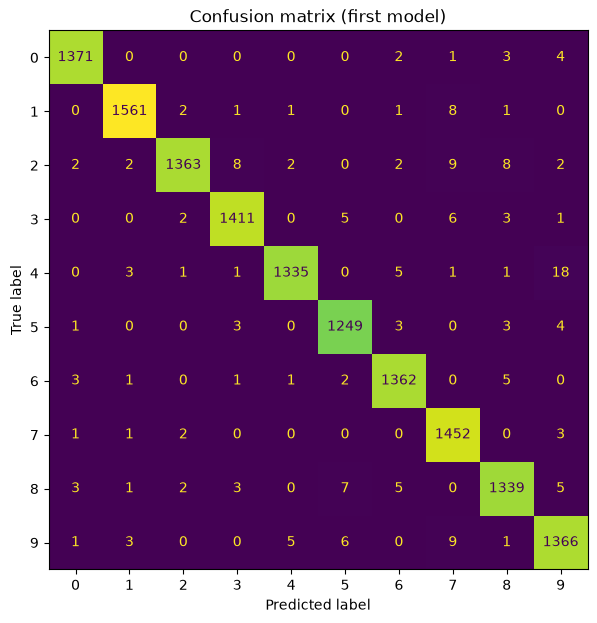

Most common mistakes (true -> predicted: count):
  4 -> 9: 18
  9 -> 7: 9
  2 -> 7: 9
  2 -> 8: 8
  1 -> 7: 8


In [10]:
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(7, 7))
ConfusionMatrixDisplay(cm, display_labels=range(10)).plot(ax=ax, colorbar=False)
ax.set_title("Confusion matrix (first model)")
plt.show()

# The largest off-diagonal cells are the most common confusions.
off_diag = cm.copy()
np.fill_diagonal(off_diag, 0)
order = np.argsort(off_diag, axis=None)[::-1][:5]
print("Most common mistakes (true -> predicted: count):")
for true_digit, pred_digit in zip(*np.unravel_index(order, cm.shape)):
    print(f"  {true_digit} -> {pred_digit}: {off_diag[true_digit, pred_digit]}")

### Findings

The first model reached a test accuracy of 98.64%, which leaves 191 mistakes out of 14,000 test images. By far the most common confusion is a true **4 predicted as 9 (18 images)**. The next is a true **9 predicted as 7 (9 images)**, tied with 2 predicted as 7, also 9. A 4 written with a closed top looks almost exactly like a 9, and a 9 with a small or open loop and a straight stem is very close to a 7, so in both pairs a few pixels at the top of the digit decide the answer.

## Part D. One change: a deeper network

The second model adds one extra `Conv2D(64)` + `MaxPooling2D` block before `Flatten` (Option A). Everything else is unchanged.

**Prediction:** I predict that the test accuracy will go up slightly, by a few tenths of a percentage point, because a second convolutional layer can combine the simple edges found by the first layer into larger shapes such as loops and closed tops. That is exactly the kind of detail that separates the digits in my two confusion pairs, so I also expect the counts for both pairs to fall, although some of these mistakes come from genuinely ambiguous handwriting and will not disappear completely."

In [11]:
# Same as the first model, plus one extra Conv2D(64) + MaxPooling2D block.
keras.utils.set_random_seed(42)

model2 = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.3),
    layers.Conv2D(64, (3, 3), activation="relu"),   # added (Option A)
    layers.MaxPooling2D((2, 2)),                    # added (Option A)
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax"),
])

model2.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
# Compiled and trained exactly as the first model.
model2.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

early_stop2 = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=3, restore_best_weights=True)

history2 = model2.fit(
    X_train, y_train,
    validation_split=0.1,
    epochs=15,
    batch_size=128,
    callbacks=[early_stop2],
    verbose=2,
)

Epoch 1/15


394/394 - 8s - 19ms/step - accuracy: 0.9087 - loss: 0.3047 - val_accuracy: 0.9723 - val_loss: 0.0857


Epoch 2/15


394/394 - 6s - 16ms/step - accuracy: 0.9756 - loss: 0.0806 - val_accuracy: 0.9795 - val_loss: 0.0637


Epoch 3/15


...

394/394 - 7s - 17ms/step - accuracy: 0.9911 - loss: 0.0278 - val_accuracy: 0.9857 - val_loss: 0.0478


Epoch 8/15


394/394 - 6s - 16ms/step - accuracy: 0.9921 - loss: 0.0249 - val_accuracy: 0.9861 - val_loss: 0.0453


Epoch 9/15


394/394 - 7s - 17ms/step - accuracy: 0.9932 - loss: 0.0216 - val_accuracy: 0.9868 - val_loss: 0.0438


Test accuracy, first model:  0.9864  (191 errors)
Test accuracy, deeper model: 0.9862  (193 errors)


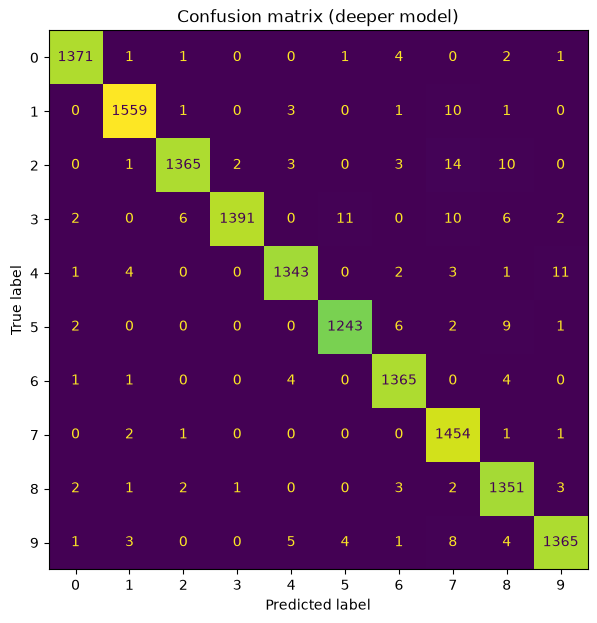

Confusion pairs from Part C (true -> predicted): before -> after
  4 -> 9: 18 -> 11
  9 -> 7: 9 -> 8
Total off-diagonal errors: 191 -> 193


In [13]:
test_loss2, test_accuracy2 = model2.evaluate(X_test, y_test, verbose=0)
print(f"Test accuracy, first model:  {test_accuracy:.4f}  ({round((1 - test_accuracy) * len(y_test))} errors)")
print(f"Test accuracy, deeper model: {test_accuracy2:.4f}  ({round((1 - test_accuracy2) * len(y_test))} errors)")

y_pred2 = model2.predict(X_test, verbose=0).argmax(axis=1)
cm2 = confusion_matrix(y_test, y_pred2)

fig, ax = plt.subplots(figsize=(7, 7))
ConfusionMatrixDisplay(cm2, display_labels=range(10)).plot(ax=ax, colorbar=False)
ax.set_title("Confusion matrix (deeper model)")
plt.show()

# Compare the two confusion pairs from Part C (and the top mistakes overall).
off_diag2 = cm2.copy()
np.fill_diagonal(off_diag2, 0)
pairs = [tuple(p) for p in zip(*np.unravel_index(order[:2], cm.shape))]
print("Confusion pairs from Part C (true -> predicted): before -> after")
for t, p in pairs:
    print(f"  {t} -> {p}: {cm[t, p]} -> {cm2[t, p]}")
print("Total off-diagonal errors:", off_diag.sum(), "->", off_diag2.sum())

### Ethical considerations

MNIST was collected mostly from American Census Bureau staff and high-school students, so people who write digits differently are under-represented. That includes the European 1 with a long upstroke, the crossed 7, children, older people and people with motor impairments, and the model is likely to misread their digits more often. In a postcode or account-number pipeline, a confident but wrong reading is worse than a refusal, because nobody checks it. A misread 4 becomes a 9, and a letter or payment is silently routed to the wrong place. A real system should therefore send low-confidence predictions to a human and should be tested on handwriting from the people who will actually use it.

## Conclusion

My first model made most of its mistakes on digits whose shapes overlap. The largest error was 4 read as 9 (18 times), followed by 9 read as 7 (9 times). My prediction in Part D was only partly correct. The deeper network (Option A) did **not** raise the test accuracy: it scored 98.62% against 98.64%, with 193 errors against 191, a difference of two images that is well within the randomness of training. It did, however, move the mistakes. The 4 → 9 confusion fell from **18 to 11**, while 9 → 7 barely changed, going from **9 to 8**. The total number of errors stayed the same, so the extra convolutional layer helped the model separate open from closed tops on 4s and 9s, but it made a similar number of new mistakes elsewhere. The drop from 18 to 11 is the only change large enough to suggest a real effect, and even that comes from one training run with a single seed. To confirm it, I would retrain both models with several seeds and compare the average counts.